In [2]:
from req_functions_from_ApproxSP import *
import pandas as pd
from AccompliceManipulation import *

100%|██████████| 6/6 [21:08<00:00, 211.43s/it]

[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.922, 1.136, 0.832, 0.43, 0.164], [0.0, 1.05, 1.416, 1.34, 0.766, 0.436], [0.0, 0.778, 1.396, 1.768, 1.474, 0.826], [0.0, 0.386, 0.702, 1.288, 2.02, 1.968], [0.0, 0.088, 0.338, 0.532, 1.41, 2.466]]


In [2]:
import pandas as pd

In [3]:
import ast
import tqdm


In [4]:
df = pd.read_csv("mallows_gain_test.csv")

In [7]:
results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matchings"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
            new_matching = func_return[0]
            accomplice_pref_after = func_return[1]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = rk1 - rk2  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["accomplice_results"] = results
df.to_csv('mallows_gain_test.csv', index=False)


TypeError: 'module' object is not callable

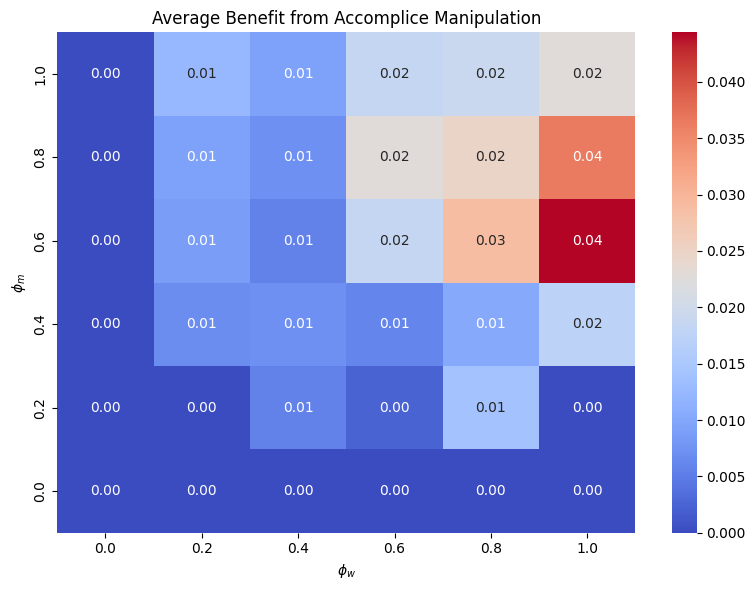

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


phi_m_list = []
phi_w_list = []
avg_benefit_list = []


for i, row in df.iterrows():
    accomplice_results = row["accomplice_results"]


    benefits = [
        result[0]  # benefit value
        for manipulator_results in accomplice_results
        for result in manipulator_results
    ]

    avg_benefit = np.mean(benefits)

    phi_m_list.append(round(row["phi_m"], 2))
    phi_w_list.append(round(row["phi_w"], 2))
    avg_benefit_list.append(avg_benefit)


heatmap_df = pd.DataFrame({
    "phi_m": phi_m_list,
    "phi_w": phi_w_list,
    "avg_benefit": avg_benefit_list
})


heatmap_matrix = heatmap_df.pivot_table(index="phi_m", columns="phi_w", values="avg_benefit", aggfunc='mean')



plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Benefit from Accomplice Manipulation")
plt.xlabel(r'$\phi_w$')
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


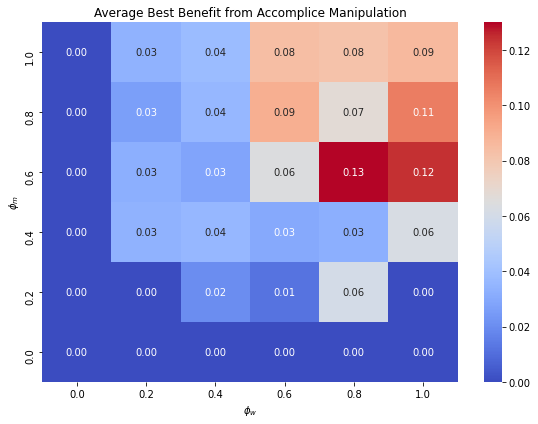

In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
# df = pd.read_csv("your_file.csv")  # Uncomment and set filename if needed

# Prepare lists to store the new columns
best_benefits_list = []
avg_best_benefit_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    accomplice_results = row["accomplice_results"]
    if isinstance(accomplice_results, str):
        accomplice_results = ast.literal_eval(accomplice_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in accomplice_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    avg_best_benefit_list.append(np.mean(best_benefits_per_woman))

# Add new columns to the original DataFrame
df["best_benefits_per_woman"] = best_benefits_list
df["avg_best_benefit"] = avg_best_benefit_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("updated_results_with_new_columns.csv", index=False)

# --- Heatmap: average across samples for each phi_m, phi_w ---
heatmap_df = df.groupby(["phi_m", "phi_w"])["avg_best_benefit"].mean().reset_index()

heatmap_matrix = heatmap_df.pivot_table(
    index="phi_m",
    columns="phi_w",
    values="avg_best_benefit",
    aggfunc="mean"
)

plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Best Benefit from Accomplice Manipulation")
plt.xlabel(r'$\phi_w$')
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


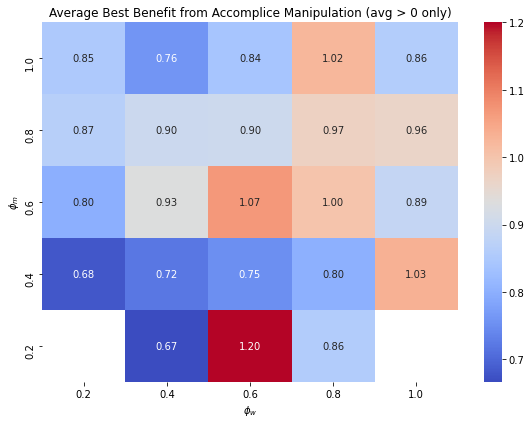

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
# df = pd.read_csv("your_file.csv")  # Uncomment and set filename if needed

# Prepare lists to store the new columns
best_benefits_list = []
avg_best_benefit_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    accomplice_results = row["accomplice_results"]
    if isinstance(accomplice_results, str):
        accomplice_results = ast.literal_eval(accomplice_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in accomplice_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    avg_best_benefit_list.append(np.mean(best_benefits_per_woman))

# Add new columns to the original DataFrame
df["best_benefits_per_woman"] = best_benefits_list
df["avg_best_benefit"] = avg_best_benefit_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("updated_results_with_new_columns.csv", index=False)

# 🔹 Filter only rows with avg_best_benefit > 0
df_filtered = df[df["avg_best_benefit"] > 0]

# --- Heatmap: average across samples for each phi_m, phi_w ---
heatmap_df = df_filtered.groupby(["phi_m", "phi_w"])["avg_best_benefit"].mean().reset_index()

heatmap_matrix = heatmap_df.pivot_table(
    index="phi_m",
    columns="phi_w",
    values="avg_best_benefit",
    aggfunc="mean"
)

plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Best Benefit from Accomplice Manipulation (avg > 0 only)")
plt.xlabel(r'$\phi_w$')
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


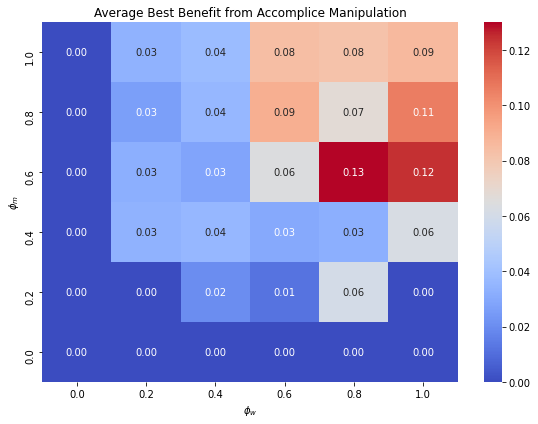

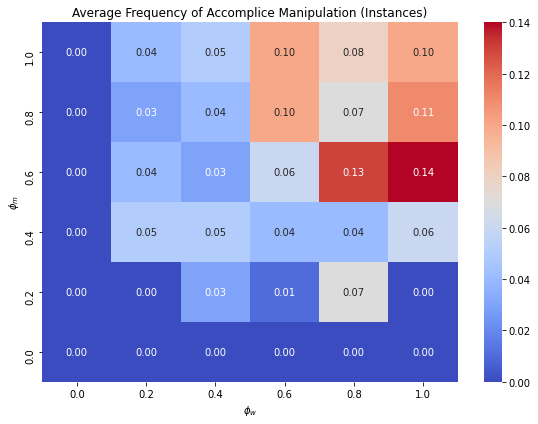

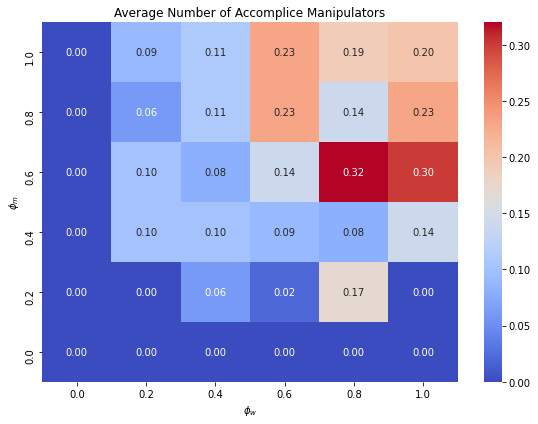

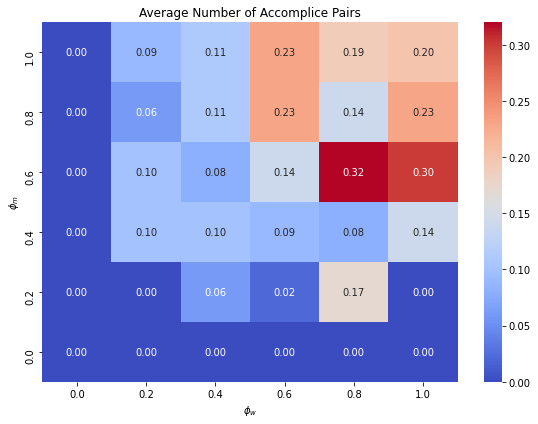

In [10]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
# df = pd.read_csv("your_file.csv")  # Uncomment and set filename if needed

# Prepare lists to store the new columns
best_benefits_list = []
avg_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    accomplice_results = row["accomplice_results"]
    if isinstance(accomplice_results, str):
        accomplice_results = ast.literal_eval(accomplice_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in accomplice_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    avg_val = np.mean(best_benefits_per_woman)
    avg_best_benefit_list.append(avg_val)

    # --- New columns ---
    # 1. acc_freq_instance
    acc_freq_instance_list.append(1 if avg_val > 0 else 0)

    # 2. number_acc_pairs: manipulator has accomplice with benefit > 0
    num_pairs = sum(
        any(result[0] > 0 for result in manipulator_results)
        for manipulator_results in accomplice_results
    )
    number_acc_pairs_list.append(num_pairs)

    # 3. number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman"] = best_benefits_list
df["avg_best_benefit"] = avg_best_benefit_list
df["acc_freq_instance"] = acc_freq_instance_list
df["number_acc_pairs"] = number_acc_pairs_list
df["number_acc_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("updated_results_with_new_columns.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].mean().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()
    plt.show()

# --- Generate the 4 plots ---
plot_heatmap(df, "avg_best_benefit", "Average Best Benefit from Accomplice Manipulation")
plot_heatmap(df, "acc_freq_instance", "Average Frequency of Accomplice Manipulation (Instances)")
plot_heatmap(df, "number_acc_manipulators", "Average Number of Accomplice Manipulators")
plot_heatmap(df, "number_acc_pairs", "Average Number of Accomplice Pairs")


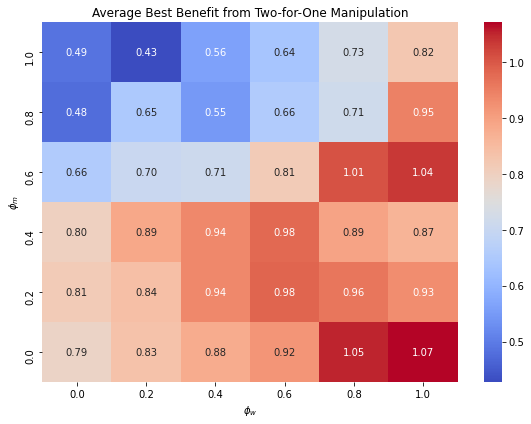

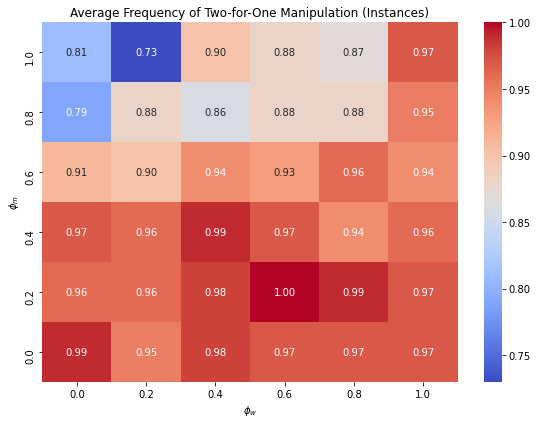

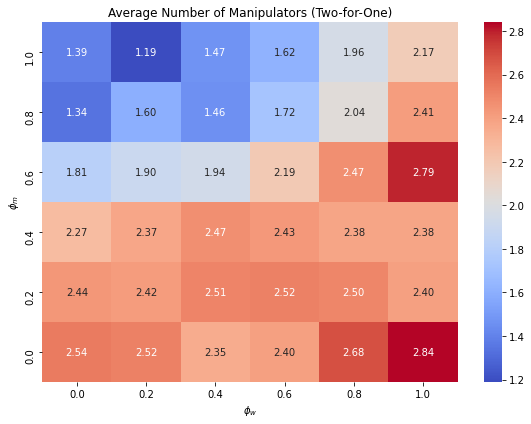

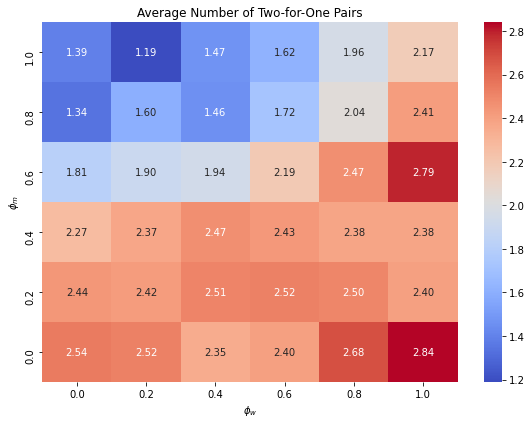

In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_gain_test2.csv")

# Prepare lists to store the new columns
best_benefits_list = []
avg_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    two_for_one_results = row["two_for_one_results"]
    if isinstance(two_for_one_results, str):
        two_for_one_results = ast.literal_eval(two_for_one_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in two_for_one_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    avg_val = np.mean(best_benefits_per_woman)
    avg_best_benefit_list.append(avg_val)

    # --- New columns ---
    acc_freq_instance_list.append(1 if avg_val > 0 else 0)

    # number_acc_pairs: manipulator has at least one accomplice with benefit > 0
    num_pairs = sum(
        any(result[0] > 0 for result in manipulator_results)
        for manipulator_results in two_for_one_results
    )
    number_acc_pairs_list.append(num_pairs)

    # number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman"] = best_benefits_list
df["avg_best_benefit"] = avg_best_benefit_list
df["acc_freq_instance"] = acc_freq_instance_list
df["number_acc_pairs"] = number_acc_pairs_list
df["number_acc_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("mallows_gain_test2_updated.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].mean().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()
    plt.show()

# --- Generate the 4 plots ---
plot_heatmap(df, "avg_best_benefit", "Average Best Benefit from Two-for-One Manipulation")
plot_heatmap(df, "acc_freq_instance", "Average Frequency of Two-for-One Manipulation (Instances)")
plot_heatmap(df, "number_acc_manipulators", "Average Number of Manipulators (Two-for-One)")
plot_heatmap(df, "number_acc_pairs", "Average Number of Two-for-One Pairs")
